In [3]:
from google.colab import drive
import pandas as pd

# 1. Conecta o Google Drive (está correto!)
drive.mount('/content/drive')

# 2. Caminho ajustado com o nome exato da sua pasta
caminho = '/content/drive/MyDrive/mineracao-dados-supply-chain/DataCoSupplyChainDataset.csv'

# 3. Lê a base de dados
df = pd.read_csv(caminho, encoding='latin-1')

# 4. Exibe as 5 primeiras linhas
df.head()

Mounted at /content/drive


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [6]:
# 1. Verifica a distribuição da variável alvo principal (Late_delivery_risk)
print("--- Distribuição de Late_delivery_risk (Contagem Absoluta) ---")
print(df['Late_delivery_risk'].value_counts())

print("\n--- Distribuição Percentual (%) ---")
print(df['Late_delivery_risk'].value_counts(normalize=True) * 100)

--- Distribuição de Late_delivery_risk (Contagem Absoluta) ---
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

--- Distribuição Percentual (%) ---
Late_delivery_risk
1    54.829132
0    45.170868
Name: proportion, dtype: float64


--- Taxa de Risco de Atraso (%) por Modalidade de Envio ---
Late_delivery_risk      0      1
Shipping Mode                   
First Class          4.68  95.32
Same Day            54.26  45.74
Second Class        23.37  76.63
Standard Class      61.93  38.07


/tmp/ipykernel_833/86350368.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.countplot(data=df, x='Late_delivery_risk', palette=['#2ecc71', '#e74c3c'], ax=axes[0])
/tmp/ipykernel_833/86350368.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Sem Risco (0)', 'Com Risco (1)'])


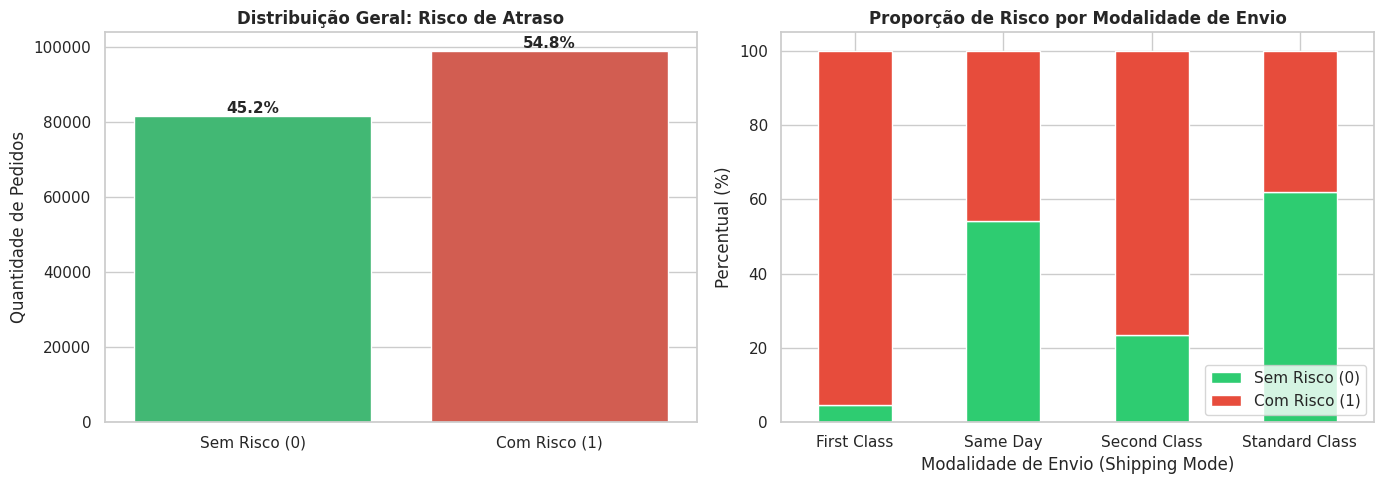

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cruzamento: Taxa de atraso por Modalidade de Envio (Shipping Mode)
print("--- Taxa de Risco de Atraso (%) por Modalidade de Envio ---")
risco_por_modalidade = pd.crosstab(df['Shipping Mode'], df['Late_delivery_risk'], normalize='index') * 100
print(risco_por_modalidade.round(2))

# 2. Configuração visual dos gráficos para o portfólio
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Distribuição Geral do Target
ax1 = sns.countplot(data=df, x='Late_delivery_risk', palette=['#2ecc71', '#e74c3c'], ax=axes[0])
axes[0].set_title('Distribuição Geral: Risco de Atraso', fontsize=12, fontweight='bold')
axes[0].set_xticklabels(['Sem Risco (0)', 'Com Risco (1)'])
axes[0].set_xlabel('')
axes[0].set_ylabel('Quantidade de Pedidos')

# Adiciona os percentuais em cima das barras
total = len(df)
for p in ax1.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax1.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

# Gráfico 2: Risco de Atraso por Modalidade de Envio
risco_plot = pd.crosstab(df['Shipping Mode'], df['Late_delivery_risk'], normalize='index') * 100
risco_plot.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], ax=axes[1])
axes[1].set_title('Proporção de Risco por Modalidade de Envio', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Modalidade de Envio (Shipping Mode)')
axes[1].set_ylabel('Percentual (%)')
axes[1].legend(['Sem Risco (0)', 'Com Risco (1)'], loc='lower right')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
# Salva a imagem em alta resolução diretamente no ambiente do Colab
plt.savefig('02_eda_risco_atraso.png', dpi=300)
plt.show()

In [8]:
# 1. Verifica linhas totalmente duplicadas
duplicados = df.duplicated().sum()
print(f"Total de linhas duplicadas: {duplicados}")

# 2. Mapeia colunas com valores nulos (ausentes)
nulos = df.isnull().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)

print("\n--- Colunas com Valores Nulos ---")
if len(nulos) == 0:
    print("Nenhum valor nulo encontrado.")
else:
    for col, qtd in nulos.items():
        pct = (qtd / len(df)) * 100
        print(f"{col}: {qtd} nulos ({pct:.2f}%)")

# 3. Lista todas as 53 colunas e seus tipos de dados para triagem de negócio
print("\n--- Listagem Geral das Colunas e Tipos ---")
for i, (col, dtype) in enumerate(df.dtypes.items()):
    print(f"{i:02d}. {col} ({dtype})")

Total de linhas duplicadas: 0

--- Colunas com Valores Nulos ---
Product Description: 180519 nulos (100.00%)
Order Zipcode: 155679 nulos (86.24%)
Customer Lname: 8 nulos (0.00%)
Customer Zipcode: 3 nulos (0.00%)

--- Listagem Geral das Colunas e Tipos ---
00. Type (object)
01. Days for shipping (real) (int64)
02. Days for shipment (scheduled) (int64)
03. Benefit per order (float64)
04. Sales per customer (float64)
05. Delivery Status (object)
06. Late_delivery_risk (int64)
07. Category Id (int64)
08. Category Name (object)
09. Customer City (object)
10. Customer Country (object)
11. Customer Email (object)
12. Customer Fname (object)
13. Customer Id (int64)
14. Customer Lname (object)
15. Customer Password (object)
16. Customer Segment (object)
17. Customer State (object)
18. Customer Street (object)
19. Customer Zipcode (float64)
20. Department Id (int64)
21. Department Name (object)
22. Latitude (float64)
23. Longitude (float64)
24. Market (object)
25. Order City (object)
26. Order C

In [9]:
import pandas as pd

# Cria uma cópia de segurança para o dataset limpo
df_clean = df.copy()

# 1. Engenharia de Features Temporais (antes de apagar a data)
df_clean['order_date_dt'] = pd.to_datetime(df_clean['order date (DateOrders)'])
df_clean['Order_Month'] = df_clean['order_date_dt'].dt.month
df_clean['Order_DayOfWeek'] = df_clean['order_date_dt'].dt.dayofweek # 0=Segunda, 6=Domingo
df_clean['Order_Hour'] = df_clean['order_date_dt'].dt.hour

# 2. Lista de colunas para descarte (Nulos, Leakage, PII, IDs e Redundâncias)
colunas_remover = [
    # Nulos severos
    'Product Description', 'Order Zipcode',
    # Data Leakage (informações do futuro)
    'Days for shipping (real)', 'Delivery Status', 'Order Status', 'shipping date (DateOrders)',
    # Dados pessoais (LGPD) e ruído
    'Customer Email', 'Customer Fname', 'Customer Lname', 'Customer Password',
    'Customer Street', 'Product Image', 'Customer Zipcode', 'Product Status',
    # IDs sem valor preditivo
    'Customer Id', 'Order Customer Id', 'Order Id', 'Order Item Id',
    'Order Item Cardprod Id', 'Product Card Id', 'Category Id',
    'Product Category Id', 'Department Id',
    # Redundâncias diretas e coluna auxiliar de data
    'order date (DateOrders)', 'order_date_dt', 'Order Item Product Price',
    'Order Profit Per Order', 'Sales per customer', 'Order Item Total'
]

df_clean = df_clean.drop(columns=colunas_remover)

# 3. Verificação final da base limpa
print(f"Dimensão original: {df.shape}")
print(f"Dimensão após limpeza e feature engineering: {df_clean.shape}")
print(f"Total de valores nulos restantes: {df_clean.isnull().sum().sum()}")
print("\n--- Colunas Selecionadas para Modelagem ---")
print(list(df_clean.columns))

Dimensão original: (180519, 53)
Dimensão após limpeza e feature engineering: (180519, 28)
Total de valores nulos restantes: 0

--- Colunas Selecionadas para Modelagem ---
['Type', 'Days for shipment (scheduled)', 'Benefit per order', 'Late_delivery_risk', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Region', 'Order State', 'Product Name', 'Product Price', 'Shipping Mode', 'Order_Month', 'Order_DayOfWeek', 'Order_Hour']


In [10]:
# Identifica todas as colunas de texto (categóricas) e conta quantos valores únicos cada uma tem
colunas_categoricas = df_clean.select_dtypes(include=['object']).columns

print("--- Cardinalidade das Variáveis Categóricas ---")
for col in colunas_categoricas:
    qtd_unicos = df_clean[col].nunique()
    print(f"{col}: {qtd_unicos} categorias únicas")

--- Cardinalidade das Variáveis Categóricas ---
Type: 4 categorias únicas
Category Name: 50 categorias únicas
Customer City: 563 categorias únicas
Customer Country: 2 categorias únicas
Customer Segment: 3 categorias únicas
Customer State: 46 categorias únicas
Department Name: 11 categorias únicas
Market: 5 categorias únicas
Order City: 3597 categorias únicas
Order Country: 164 categorias únicas
Order Region: 23 categorias únicas
Order State: 1089 categorias únicas
Product Name: 118 categorias únicas
Shipping Mode: 4 categorias únicas


In [11]:
from sklearn.model_selection import train_test_split

# 1. Remove colunas de localização de altíssima cardinalidade do dataset limpo
colunas_geo_remover = ['Order City', 'Order State', 'Order Country']
df_model = df_clean.drop(columns=colunas_geo_remover)

# 2. Separa as variáveis preditoras (X) e a variável alvo (y)
X = df_model.drop(columns=['Late_delivery_risk'])
y = df_model['Late_delivery_risk']

# 3. Divide em treino (80%) e teste (20%) mantendo a proporção das classes de y
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Confere o tamanho dos conjuntos gerados
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (144415, 24)
X_test: (36104, 24)
y_train: (144415,)
y_test: (36104,)
